# TSA Operational Performance

## Introduction

This analysis is tailored for Federal Security Directors (FSDs) and TSA Regional Operations Managers. This is an internal audience with high data literacy and intimate knowledge of airport operations, codes (IATA/ICAO), and screening protocols. They expect clear, objective metrics rather than superficial infographics.

This report moves beyond simple information sharing to provide a direct Call to Action. To identify acute, localized operational failures across US airports and secure executive approval for targeted resource reallocation, specialized staff retraining, and security infrastructure upgrades.

### 2.1 Data Preparation

Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [2]:
# Load the dataset file to Pandas DataFrame
airport = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/complaints-by-airport.csv')
category = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/complaints-by-category.csv')
subcategory = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/complaints-by-subcategory.csv')
icao = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Storytelling-with-Data/Dataset/iata-icao.csv')


In [3]:
# Preview the column names to verify structure
print(airport.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41721 entries, 0 to 41720
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   pdf_report_date  41721 non-null  object
 1   airport          41612 non-null  object
 2   year_month       41721 non-null  object
 3   count            41721 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 1.3+ MB
None


In [4]:
# Preview the column names to verify structure
print(category.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241588 entries, 0 to 241587
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   pdf_report_date   241588 non-null  object
 1   airport           237546 non-null  object
 2   category          241588 non-null  object
 3   year_month        241588 non-null  object
 4   count             241588 non-null  int64 
 5   clean_cat         241588 non-null  object
 6   clean_cat_status  241588 non-null  object
dtypes: int64(1), object(6)
memory usage: 12.9+ MB
None


In [5]:
# Preview the column names to verify structure
print(subcategory.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504512 entries, 0 to 504511
Data columns (total 11 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   pdf_report_date             504512 non-null  object
 1   airport                     491048 non-null  object
 2   category                    504512 non-null  object
 3   subcategory                 504512 non-null  object
 4   year_month                  504512 non-null  object
 5   count                       504512 non-null  int64 
 6   clean_cat                   504512 non-null  object
 7   clean_subcat                504512 non-null  object
 8   clean_cat_status            504512 non-null  object
 9   clean_subcat_status         504512 non-null  object
 10  is_category_prefix_removed  504512 non-null  bool  
dtypes: bool(1), int64(1), object(9)
memory usage: 39.0+ MB
None


In [6]:
# Preview the column names to verify structure
print(icao.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8937 entries, 0 to 8936
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  8905 non-null   object 
 1   region_name   8937 non-null   object 
 2   iata          8937 non-null   object 
 3   icao          7794 non-null   object 
 4   airport       8937 non-null   object 
 5   latitude      8937 non-null   float64
 6   longitude     8937 non-null   float64
dtypes: float64(2), object(5)
memory usage: 488.9+ KB
None


In [7]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(airport.head())


The first five rows of data:
  pdf_report_date airport year_month  count
0         2019-02     ABE    2015-01      0
1         2019-02     ABE    2015-02      0
2         2019-02     ABE    2015-03      0
3         2019-02     ABE    2015-04      0
4         2019-02     ABE    2015-05      2


In [8]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(category.head())


The first five rows of data:
  pdf_report_date airport                           category year_month  \
0         2019-02     ABE         Hazardous Materials Safety    2015-01   
1         2019-02     ABE  Mishandling of Passenger Property    2015-01   
2         2019-02     ABE         Hazardous Materials Safety    2015-02   
3         2019-02     ABE  Mishandling of Passenger Property    2015-02   
4         2019-02     ABE         Hazardous Materials Safety    2015-03   

   count                          clean_cat clean_cat_status  
0      0         Hazardous Materials Safety         original  
1      0  Mishandling of Passenger Property         original  
2      0         Hazardous Materials Safety         original  
3      0  Mishandling of Passenger Property         original  
4      0         Hazardous Materials Safety         original  


In [9]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(subcategory.head())


The first five rows of data:
  pdf_report_date airport                           category  \
0         2019-02     ABE         Hazardous Materials Safety   
1         2019-02     ABE  Mishandling of Passenger Property   
2         2019-02     ABE         Hazardous Materials Safety   
3         2019-02     ABE  Mishandling of Passenger Property   
4         2019-02     ABE         Hazardous Materials Safety   

                              subcategory year_month  count  \
0                                 General    2015-01      0   
1  Damaged/Missing Items--Checked Baggage    2015-01      0   
2                                 General    2015-02      0   
3  Damaged/Missing Items--Checked Baggage    2015-02      0   
4                                 General    2015-03      0   

                           clean_cat                             clean_subcat  \
0         Hazardous Materials Safety                                  General   
1  Mishandling of Passenger Property  *Damag

In [10]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(icao.head())


The first five rows of data:
  country_code region_name iata  icao                          airport  \
0           AE    Abu Zaby  AAN  OMAL     Al Ain International Airport   
1           AE    Abu Zaby  AUH  OMAA  Abu Dhabi International Airport   
2           AE    Abu Zaby  AYM   NaN         Yas Island Seaplane Base   
3           AE    Abu Zaby  AZI  OMAD      Al Bateen Executive Airport   
4           AE    Abu Zaby  DHF  OMAM               Al Dhafra Air Base   

   latitude  longitude  
0   24.2617    55.6092  
1   24.4330    54.6511  
2   24.4670    54.6103  
3   24.4283    54.4581  
4   24.2482    54.5477  


#### 2.1(a) Check for missing values

In [11]:
# Using .isnull() to find missing values
airport.isnull().sum()


pdf_report_date      0
airport            109
year_month           0
count                0
dtype: int64

In [12]:
# Using .isnull() to find missing values
category.isnull().sum()


pdf_report_date        0
airport             4042
category               0
year_month             0
count                  0
clean_cat              0
clean_cat_status       0
dtype: int64

In [13]:
# Using .isnull() to find missing values
subcategory.isnull().sum()


pdf_report_date                   0
airport                       13464
category                          0
subcategory                       0
year_month                        0
count                             0
clean_cat                         0
clean_subcat                      0
clean_cat_status                  0
clean_subcat_status               0
is_category_prefix_removed        0
dtype: int64

In [14]:
# Using .isnull() to find missing values
icao.isnull().sum()


country_code      32
region_name        0
iata               0
icao            1143
airport            0
latitude           0
longitude          0
dtype: int64

Datasets with some missing values. 

#### 2.1(b) Normalization Pipeline

In [15]:
# Group overall airport baseline counts to find total volume per airport
airport_totals = airport.groupby('airport')['count'].sum().reset_index().rename(columns={'count': 'total_traffic'})

# Merge categories with IATA/ICAO coordinates and traffic data
cat_merged = category.merge(airport_totals, on='airport', how='inner')
cat_merged = cat_merged.merge(icao, left_on='airport', right_on='iata', how='inner', suffixes=('', '_geo'))

# Calculate a Normalized Metric: Complaints per 100,000 traffic units
cat_merged['complaints_per_100k'] = (cat_merged['count'] / cat_merged['total_traffic']) * 100000

# Set plotting style for professional scannability
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})
ALERT_COLOR = "#D95F02"  # Muted amber/red for out-of-bounds metrics
NEUTRAL_COLOR = "#7570B3" # Slate purple/gray for baseline metrics

In [16]:
# Preview the column names to verify structure
print(cat_merged.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 236543 entries, 0 to 236542
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   pdf_report_date      236543 non-null  object 
 1   airport              236543 non-null  object 
 2   category             236543 non-null  object 
 3   year_month           236543 non-null  object 
 4   count                236543 non-null  int64  
 5   clean_cat            236543 non-null  object 
 6   clean_cat_status     236543 non-null  object 
 7   total_traffic        236543 non-null  int64  
 8   country_code         236543 non-null  object 
 9   region_name          236543 non-null  object 
 10  iata                 236543 non-null  object 
 11  icao                 236456 non-null  object 
 12  airport_geo          236543 non-null  object 
 13  latitude             236543 non-null  float64
 14  longitude            236543 non-null  float64
 15  complaints_per_10

In [17]:
# Display the first 5 rows of the data set
print("\nThe first five rows of data:")
print(cat_merged.head())


The first five rows of data:
  pdf_report_date airport                           category year_month  \
0         2019-02     ABE         Hazardous Materials Safety    2015-01   
1         2019-02     ABE  Mishandling of Passenger Property    2015-01   
2         2019-02     ABE         Hazardous Materials Safety    2015-02   
3         2019-02     ABE  Mishandling of Passenger Property    2015-02   
4         2019-02     ABE         Hazardous Materials Safety    2015-03   

   count                          clean_cat clean_cat_status  total_traffic  \
0      0         Hazardous Materials Safety         original            463   
1      0  Mishandling of Passenger Property         original            463   
2      0         Hazardous Materials Safety         original            463   
3      0  Mishandling of Passenger Property         original            463   
4      0         Hazardous Materials Safety         original            463   

  country_code   region_name iata  icao     

#### 2.1(c) Check for duplicates

In [18]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate = cat_merged.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate}")


Number of duplicate rows: 0


Datasets with no duplicate rows.

### 2.2 Exploratory Data Analysis

Exploratory data analysis revealed several patterns in the dataset. Several visualizations provide clear and complementary insights into these dataset. 

#### 2.2(a) Spatial Visual / Choropleth Scatter Map

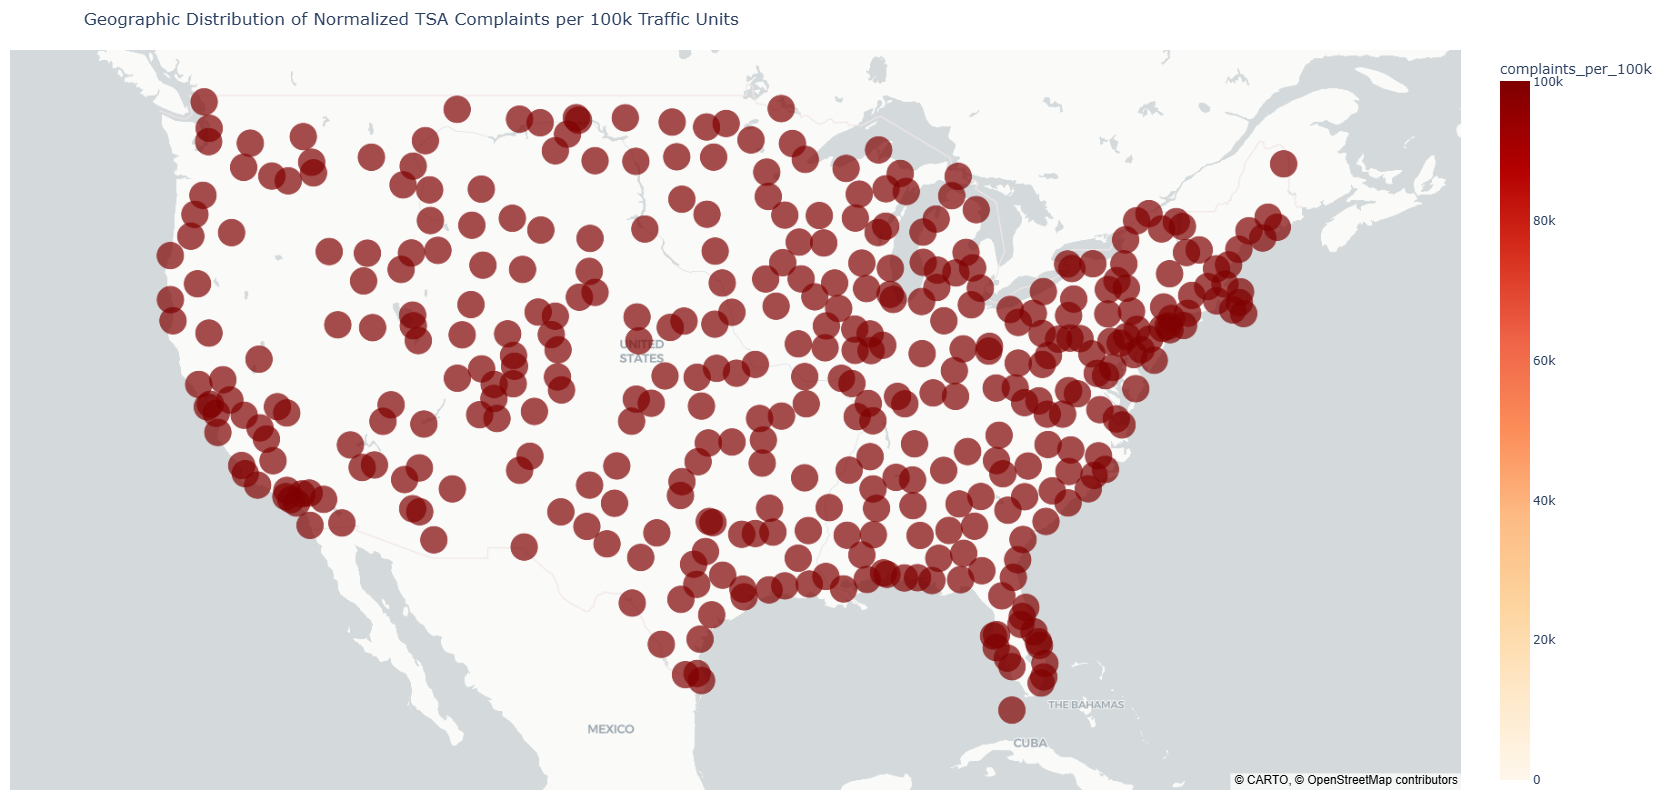

In [19]:
# Aggregating normalized rates by geographic coordinate
geo_data = cat_merged.groupby(['airport', 'latitude', 'longitude'])['complaints_per_100k'].sum().reset_index()

fig1 = px.scatter_map(
    geo_data, 
    lat="latitude", 
    lon="longitude", 
    size="complaints_per_100k",
    color="complaints_per_100k", 
    color_continuous_scale=px.colors.sequential.OrRd,
    title="Geographic Distribution of Normalized TSA Complaints per 100k Traffic Units"
)

# Force the layout to be much larger and focus tightly on the US region
fig1.update_layout(
    height=800,           # Increases vertical box size significantly (from default ~450)
    width=1200,          # Sets a crisp, wide container aspect ratio
    map=dict(
        style="carto-positron",
        center=dict(lat=37.0902, lon=-95.7129), # Centers directly on the geographic US
        zoom=3.8                                # Pulls the view in to eliminate global dead space
    ),
    margin=dict(r=10, t=50, l=10, b=10)        # Trims excess white space around the map edges
)

fig1.show() 

#### 2.2(b) Operational Matrix Heat Map

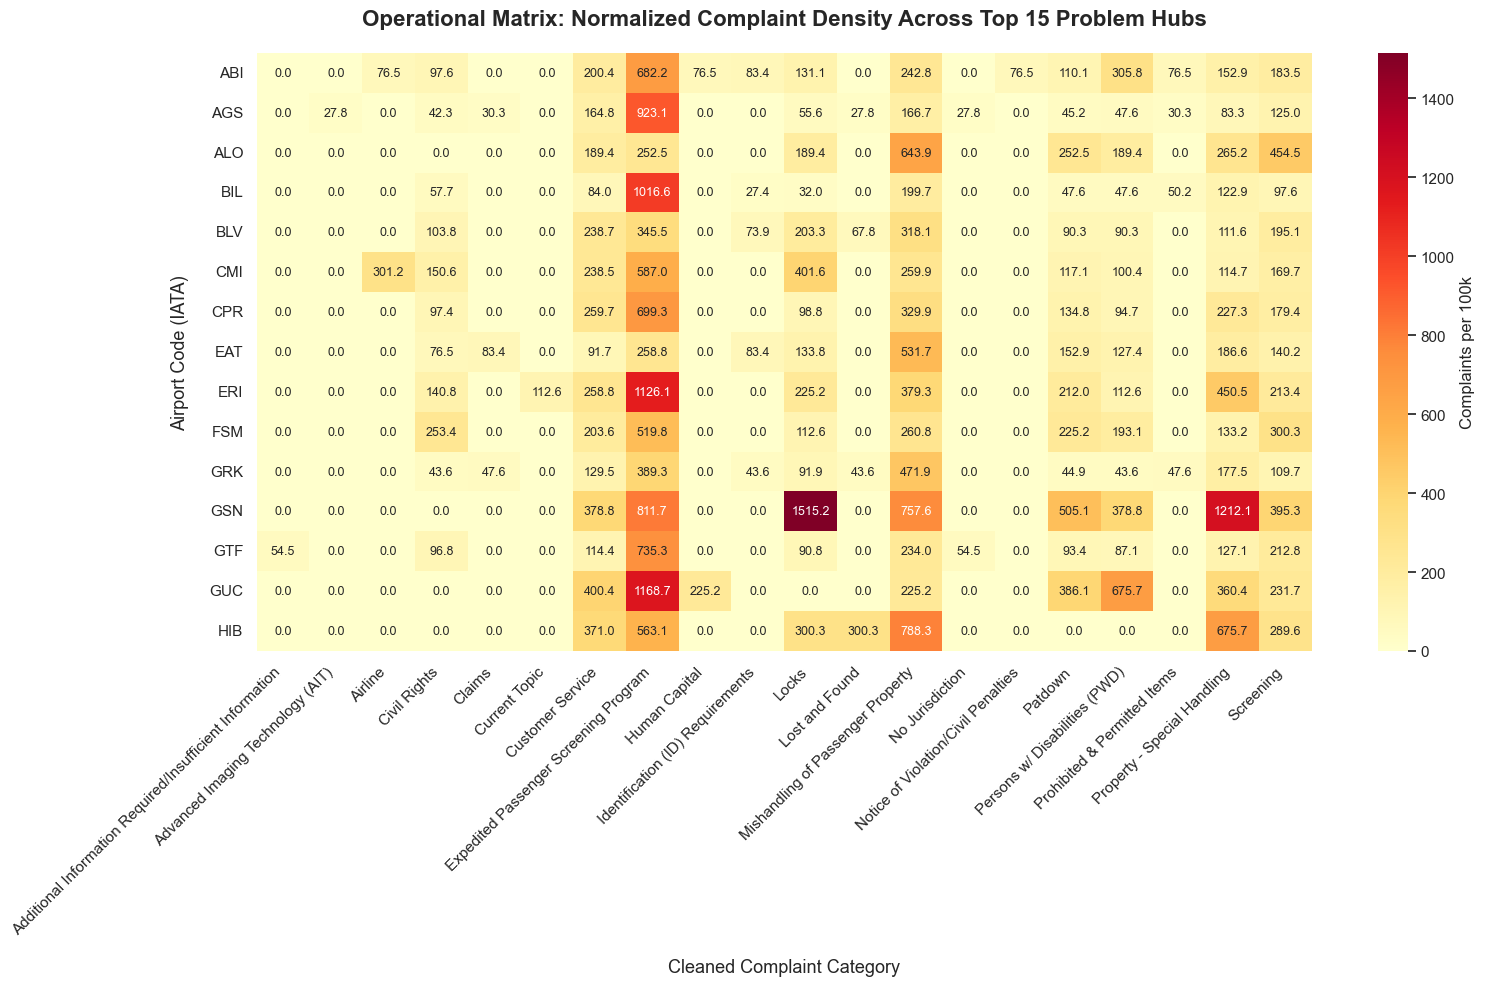

In [20]:
# Pivot data for top 15 highest-complaint airports vs clean categories
top_airports = geo_data.nlargest(15, 'complaints_per_100k')['airport']
heatmap_df = cat_merged[cat_merged['airport'].isin(top_airports)]
pivot_df = heatmap_df.pivot_table(index='airport', columns='clean_cat', values='complaints_per_100k', aggfunc='mean').fillna(0)

plt.figure(figsize=(16, 10)) 

# Generate the heatmap
ax = sns.heatmap(
    pivot_df, 
    cmap="YlOrRd", 
    annot=True, 
    fmt=".1f", 
    cbar_kws={'label': 'Complaints per 100k'},
    annot_kws={"size": 9} # Slightly smaller numbers inside cells to fit perfectly
)

# Adjust the Y-axis label properties for absolute clarity
plt.yticks(
    rotation=0,       # Keeps airport codes horizontal so they are readable
    fontsize=11,      # Ensures clean font scaling
    va='center'       # Vertically centers the text relative to each row
)

# Adjust the X-axis label rotation to prevent clipping at the bottom
plt.xticks(rotation=45, ha='right', fontsize=11)

plt.title("Operational Matrix: Normalized Complaint Density Across Top 15 Problem Hubs", weight='bold', pad=20, fontsize=16)
plt.ylabel("Airport Code (IATA)", labelpad=15, fontsize=13) # Added labelpad to push title away from codes
plt.xlabel("Cleaned Complaint Category", labelpad=15, fontsize=13)

# Adjust layout to automatically reserve space for long text labels
plt.tight_layout()
plt.show()

#### 2.2(c) Variance Detection Box Plots

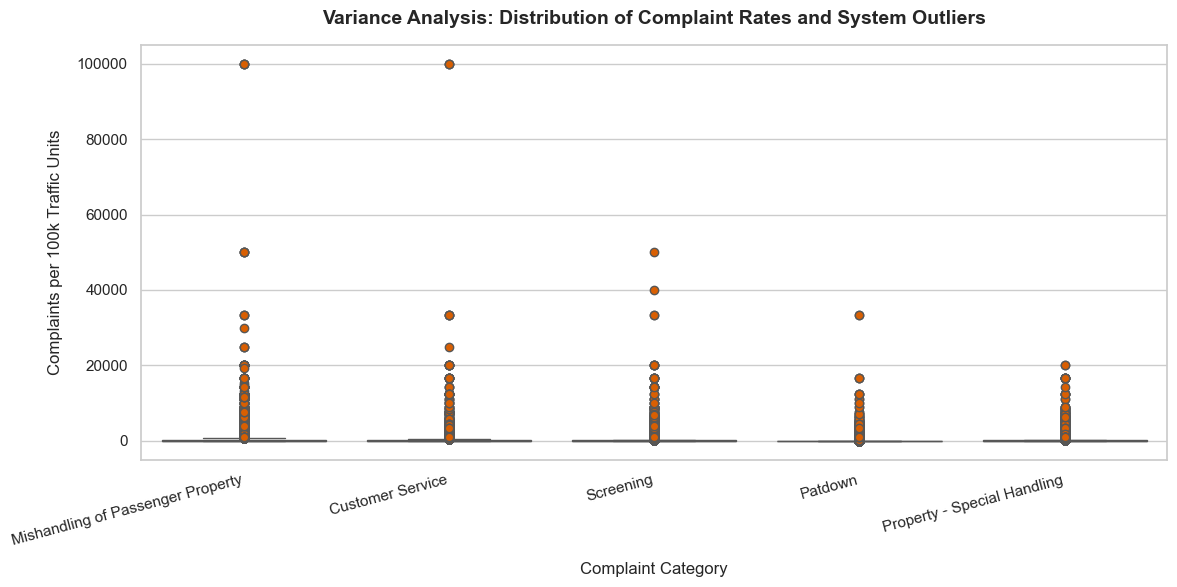

In [21]:
# Slightly wider for better category spacing
plt.figure(figsize=(12, 6)) 

if len(cat_merged['clean_cat'].unique()) > 5:
    major_cats = cat_merged['clean_cat'].value_counts().index[:5]
else:
    major_cats = cat_merged['clean_cat'].unique()

box_df = cat_merged[cat_merged['clean_cat'].isin(major_cats)]

# Generate the boxplot
sns.boxplot(
    x='clean_cat', 
    y='complaints_per_100k', 
    data=box_df, 
    color=NEUTRAL_COLOR, 
    flierprops={"markerfacecolor": ALERT_COLOR, "marker": "o", "markersize": 6}
)

plt.title("Variance Analysis: Distribution of Complaint Rates and System Outliers", weight='bold', pad=15)
plt.xlabel("Complaint Category", labelpad=10)
plt.ylabel("Complaints per 100k Traffic Units", labelpad=10)
plt.xticks(rotation=15, ha='right') # Tilts labels slightly to prevent overlapping
plt.tight_layout()
plt.show()

#### 2.2(d) Macro Trend Analysis with Line Chart

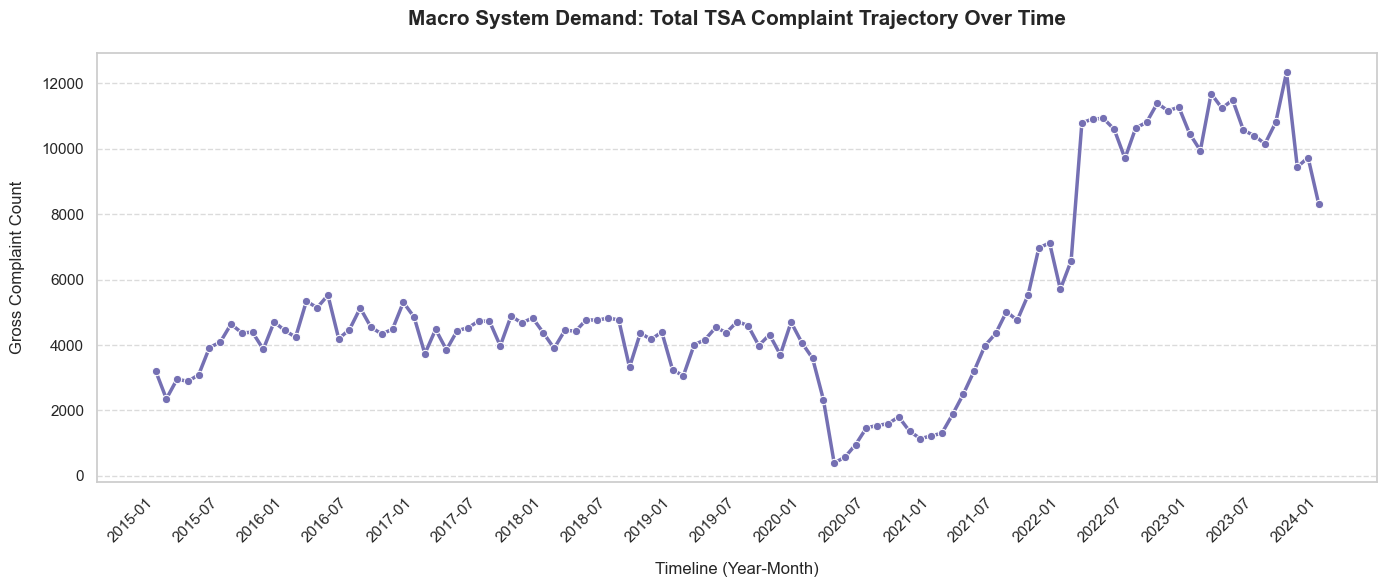

In [22]:
# Made slightly wider to give labels space
plt.figure(figsize=(14, 6))

trend_df = cat_merged.groupby('year_month')['count'].sum().reset_index()

# Sort chronologically to ensure the line flows correctly
trend_df = trend_df.sort_values('year_month').reset_index(drop=True)

# Generate the line plot without dense background vertical lines
ax = sns.lineplot(
    x='year_month', 
    y='count', 
    data=trend_df, 
    marker='o', 
    color=NEUTRAL_COLOR, 
    linewidth=2.5
)

# Turn off the vertical gridlines that create the "cage" effect
ax.xaxis.grid(False) 
ax.yaxis.grid(True, linestyle='--', alpha=0.7) # Keep clean horizontal guides

# Only display an X-axis label every 6 months to eliminate overlapping
n_months = len(trend_df)
tick_frequency = 6 
ticks_to_use = range(0, n_months, tick_frequency)
labels_to_use = [trend_df['year_month'].iloc[i] for i in ticks_to_use]

plt.xticks(
    ticks_to_use, 
    labels_to_use, 
    rotation=45, 
    ha='right', 
    fontsize=11
)

plt.title("Macro System Demand: Total TSA Complaint Trajectory Over Time", weight='bold', pad=20, fontsize=15)
plt.xlabel("Timeline (Year-Month)", labelpad=12, fontsize=12)
plt.ylabel("Gross Complaint Count", labelpad=12, fontsize=12)

plt.tight_layout()
plt.show()

#### 2.2(e) Pareto Priority Ranking Horizontal Bar Chart

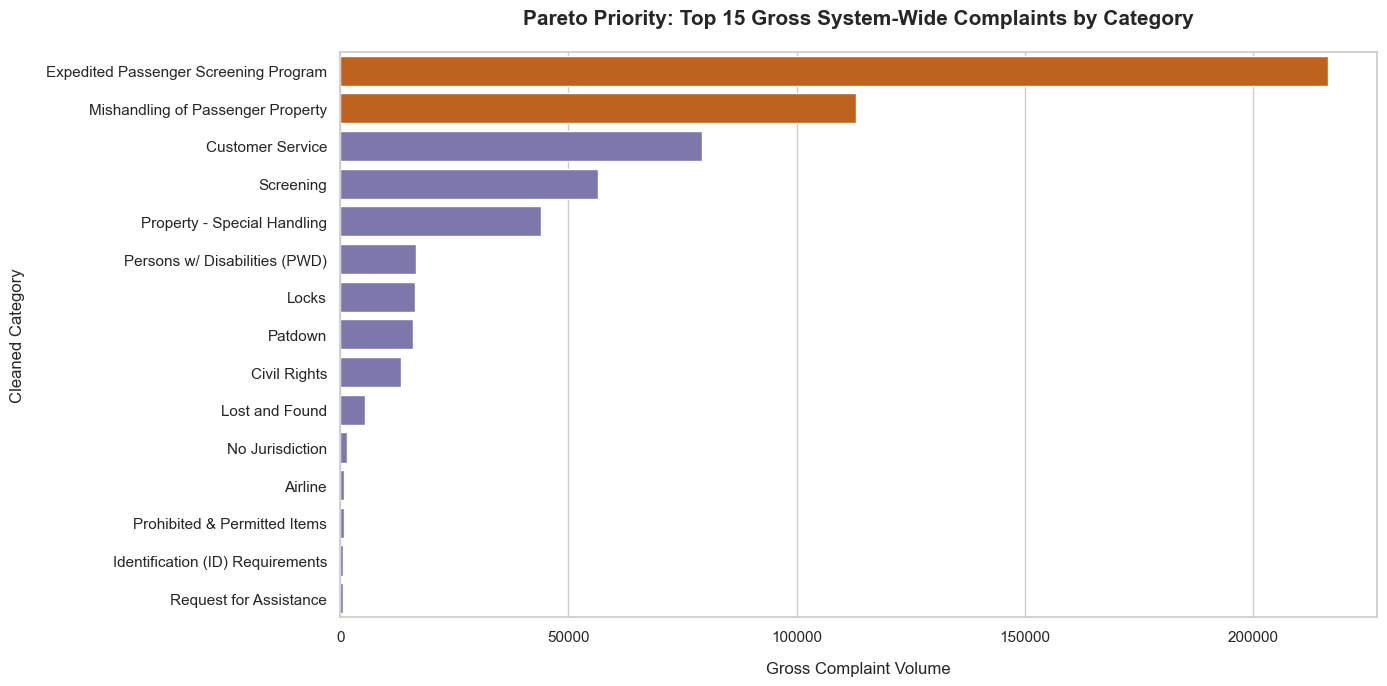

In [23]:
# Increase figure size horizontally to prevent label clipping
plt.figure(figsize=(14, 7))

# Aggregate the complaint data
cat_ranking = cat_merged.groupby('clean_cat')['count'].sum().sort_values(ascending=False).reset_index()

# Filter out categories with zero value and restrict plot to the Top 10 rows
# This instantly solves the Y-axis overlapping text problem
cat_ranking = cat_ranking[cat_ranking['count'] > 0].head(15)

# Generate matching alert colors for the top 2 categories, neutral for the rest
colors = [ALERT_COLOR if i < 2 else NEUTRAL_COLOR for i in range(len(cat_ranking))]

# Generate the barplot
sns.barplot(
    x='count', 
    y='clean_cat', 
    data=cat_ranking, 
    palette=colors, 
    hue='clean_cat', 
    legend=False
)

# Explicitly format the Y-axis labels to avoid crowd together
plt.yticks(
    fontsize=11,
    ha='right' # Right-align text cleanly against the bar edges
)

plt.title("Pareto Priority: Top 15 Gross System-Wide Complaints by Category", weight='bold', pad=20, fontsize=15)
plt.xlabel("Gross Complaint Volume", labelpad=12, fontsize=12)
plt.ylabel("Cleaned Category", labelpad=15, fontsize=12)

# Optimize spacing engine to comfortably fit the long text labels on the left
plt.tight_layout()
plt.show()

#### 2.2(f) Granular Root-Cause Resolution Subcategory Analysis Chart

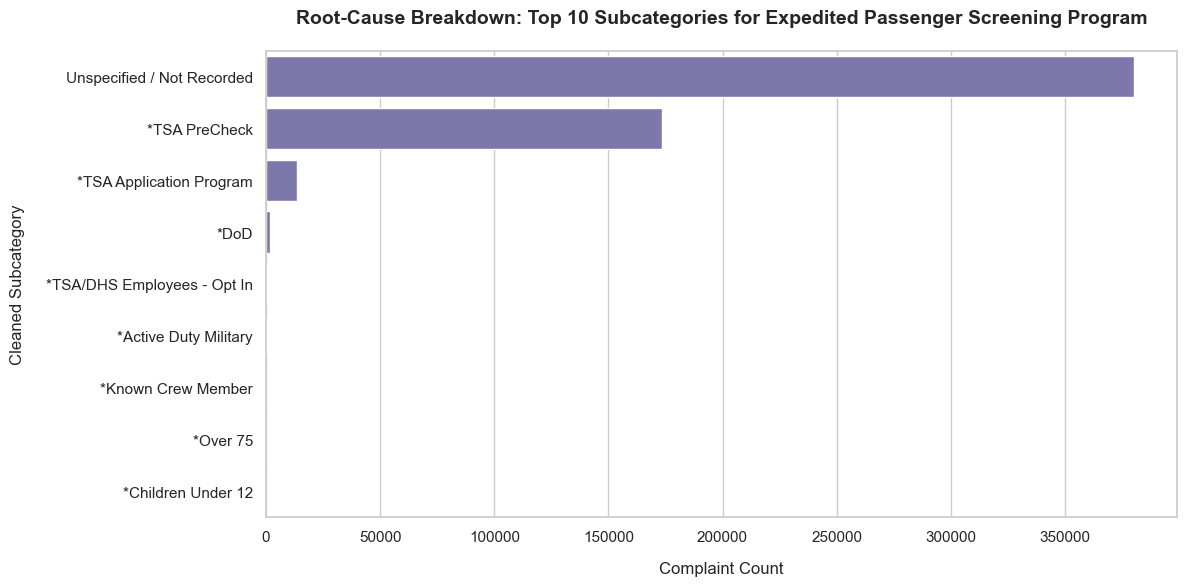

In [24]:

plt.figure(figsize=(12, 6))

# Identify the top-ranked problem category from the previous analysis step
top_severity_cat = "Expedited Passenger Screening Program"

# Isolate the data for the specific target category
sub_df_raw = subcategory[subcategory['clean_cat'] == top_severity_cat].copy()

# Replace the placeholder asterisk with a professional, descriptive label
sub_df_raw['clean_subcat'] = sub_df_raw['clean_subcat'].replace(['*', ''], 'Unspecified / Not Recorded')

# Group, aggregate, sort, and extract the top 10 rows for clean presentation
sub_df_clean = (
    sub_df_raw.groupby('clean_subcat')['count']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Generate the horizontal bar chart
sns.barplot(
    x='count', 
    y='clean_subcat', 
    data=sub_df_clean, 
    color=NEUTRAL_COLOR
)

# Adjust label text padding and font configurations for clean scannability
plt.yticks(fontsize=11)
plt.xticks(fontsize=11)

plt.title(f"Root-Cause Breakdown: Top 10 Subcategories for {top_severity_cat}", weight='bold', pad=20, fontsize=14)
plt.xlabel("Complaint Count", labelpad=12, fontsize=12)
plt.ylabel("Cleaned Subcategory", labelpad=15, fontsize=12)

# Prevent bounding box text clipping
plt.tight_layout()
plt.show()